<a href="https://colab.research.google.com/github/GUNJANSUMAN/accomadationfeedback/blob/main/problem1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DNN Programming Assignment — Problem 1: RNN, LSTM and GRU on sequences

**Student ID:** 05160 &nbsp;|&nbsp; **Individual ablation (last digit 0 → even):** gradient clipping (norm 1.0 vs none) for the vanilla RNN at T = 200

**How to run:** Runtime → Change runtime type → T4 GPU, then *Runtime → Restart and run all*. Every result is appended to `results.csv` as soon as its run finishes.

**Assumptions (also stated in the README and report)**
- Hidden size **64** and seeds **[42, 123, 2026]** are used. The variants table was not in my copy of the brief. If it gives other values, change them in Section 1.3 only.
- Epoch budgets: **30 epochs** for every HAR model and **30 epochs** for every adding-problem model. Adam, lr 1e-3, batch 128, identical for RNN, LSTM and GRU within each comparison.
- The model checkpoint kept for testing is the epoch with the best **validation** score (macro-F1 for HAR, MSE for adding). The test set is never used for selection.
- The cell-equivalence tests (Section 4) run on CPU in float32, so cuDNN kernel differences do not eat into the 1e-5 tolerance.

| Section | Brief task |
|---|---|
| 1 Setup | – |
| 2 HAR data pipeline | P1.1 |
| 3 Adding-problem generator | P1.1 |
| 4 Cells from scratch | P1.2 |
| 5 HAR classification | P1.3 |
| 6 Adding problem | P1.4 |
| 7 Gradients, ablations, analysis | P1.5 (a)–(d) |

## Section 1 — Setup

In [1]:
# 1.1 Imports
# (Colab already has these. On a fresh machine: pip install -r requirements.txt)
import os, random, time, copy, math, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

NOTEBOOK_START = time.perf_counter()
print("Imports OK")

Imports OK


In [2]:
# 1.2 Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)
if device.type == "cuda":
    print("GPU    :", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

Device : cuda
GPU    : Tesla T4
PyTorch: 2.14.1+cu130


In [3]:
# 1.3 Configuration — the only cell to edit for a different variant
STUDENT_ID = "05160"
INDIVIDUAL_ABLATION = "RNN gradient clipping (norm 1.0 vs none) at T = 200"   # last digit even

SEEDS       = [42, 123, 2026]
HIDDEN_SIZE = 64
LR          = 1e-3
BATCH_SIZE  = 128

# HAR (UCI) settings
INPUT_SIZE  = 9
SEQ_LEN_HAR = 128
NUM_CLASSES = 6
CLASS_NAMES = ["Walking", "Walk upstairs", "Walk downstairs", "Sitting", "Standing", "Laying"]
HAR_EPOCHS  = 30

# Adding problem settings
ADD_LENGTHS      = [50, 100, 200, 400]
N_TRAIN, N_VAL, N_TEST = 10_000, 1_000, 1_000
ADD_EPOCHS       = 30
MSE_BASELINE     = 0.167
SOLVED_THRESHOLD = 0.05

# Section 7 settings
T_GRADIENT  = 100
T_ABLATION  = 200
HIDDEN_SWEEP = [16, 32, 64, 128]
CLIP_NORM   = 1.0

MODELS = ["RNN", "LSTM", "GRU"]
print("Configuration set.")

Configuration set.


In [4]:
# 1.4 Reproducibility
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(SEEDS[0])

In [5]:
# 1.5 Relative paths (works from the zip root or from inside problem1/)
ROOT = Path.cwd()
if ROOT.name == "problem1":
    ROOT = ROOT.parent

DATA_DIR     = ROOT / "data"            # not submitted
P1_DIR       = ROOT / "problem1"
FIG_DIR      = P1_DIR / "figures"
RESULTS_FILE = ROOT / "results.csv"
for d in (DATA_DIR, P1_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG_DIR / name, dpi=200, bbox_inches="tight")

print("Root   :", ROOT)
print("Figures:", FIG_DIR)

Root   : /content
Figures: /content/problem1/figures


In [6]:
# 1.6 results.csv — exact columns from the brief, one row per run.
RESULT_COLUMNS = ["problem", "model", "seed", "seq_len", "test_acc", "macro_f1", "test_mse",
                  "params", "sec_per_epoch", "val_loss_nats", "bits_per_char", "notes"]

# On Restart & Run All, remove old Problem 1 rows (keep any Problem 2 rows) so nothing is duplicated.
if RESULTS_FILE.exists():
    old = pd.read_csv(RESULTS_FILE)
    old = old[~old["problem"].astype(str).str.startswith("P1")]
    old.to_csv(RESULTS_FILE, index=False)
else:
    pd.DataFrame(columns=RESULT_COLUMNS).to_csv(RESULTS_FILE, index=False)

def log_result(**kw):
    # Append one run immediately, so a Colab disconnect loses nothing.
    unknown = set(kw) - set(RESULT_COLUMNS)
    assert not unknown, f"Unknown columns: {unknown}"
    row = {c: kw.get(c, None) for c in RESULT_COLUMNS}
    pd.DataFrame([row], columns=RESULT_COLUMNS).to_csv(RESULTS_FILE, mode="a", header=False, index=False)

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print("results.csv ready:", RESULTS_FILE)

results.csv ready: /content/results.csv


## Section 2 — UCI HAR data pipeline (P1.1)
128 steps × 9 channels, 6 classes. Validation uses 4 of the 21 training subjects, drawn with `np.random.default_rng(seed)` for each seed. Per-channel mean and std come **from the training part only** and are applied to the validation and test sets.

In [7]:
# 2.1 Download and extract (skipped if already present)
HAR_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
HAR_ZIP = DATA_DIR / "har.zip"
HAR_EXTRACT = DATA_DIR / "har"

def find_har_root():
    for p in HAR_EXTRACT.rglob("UCI HAR Dataset"):
        if "__MACOSX" not in p.parts and (p / "train").is_dir():
            return p
    return None

if find_har_root() is None:
    if not HAR_ZIP.exists():
        print("Downloading UCI HAR ...")
        urllib.request.urlretrieve(HAR_URL, HAR_ZIP)
    with zipfile.ZipFile(HAR_ZIP) as z:
        z.extractall(HAR_EXTRACT)
    inner = HAR_EXTRACT / "UCI HAR Dataset.zip"     # the archive holds a second zip
    if inner.exists():
        with zipfile.ZipFile(inner) as z:
            z.extractall(HAR_EXTRACT)

HAR_DIR = find_har_root()
assert HAR_DIR is not None, "UCI HAR folder not found after extraction"
print("HAR folder:", HAR_DIR)

HAR folder: /content/data/har/UCI HAR Dataset


In [8]:
# 2.2 Load the nine inertial channels in the fixed order
CHANNELS = ["body_acc_x", "body_acc_y", "body_acc_z",
            "body_gyro_x", "body_gyro_y", "body_gyro_z",
            "total_acc_x", "total_acc_y", "total_acc_z"]

def load_split(split):
    sig_dir = HAR_DIR / split / "Inertial Signals"
    X = np.stack([np.loadtxt(sig_dir / f"{c}_{split}.txt") for c in CHANNELS], axis=-1)   # (N, 128, 9)
    y = np.loadtxt(HAR_DIR / split / f"y_{split}.txt").astype(np.int64) - 1                 # labels 0..5
    s = np.loadtxt(HAR_DIR / split / f"subject_{split}.txt").astype(np.int64)
    return X.astype(np.float32), y, s

X_train_raw, y_train_all, subj_train = load_split("train")
X_test_raw,  y_test,      subj_test  = load_split("test")

print("train:", X_train_raw.shape, " test:", X_test_raw.shape)

train: (7352, 128, 9)  test: (2947, 128, 9)


In [9]:
# Test 2.2 — shapes and subject sets match the brief
assert X_train_raw.shape == (7352, 128, 9)
assert X_test_raw.shape  == (2947, 128, 9)
assert set(np.unique(y_train_all)) == set(range(6))
assert len(np.unique(subj_train)) == 21 and len(np.unique(subj_test)) == 9
assert set(subj_train).isdisjoint(set(subj_test))
print("HAR loading tests passed.")

HAR loading tests passed.


In [10]:
# 2.3 Subject-wise validation split
TRAIN_SUBJECTS = np.unique(subj_train)

def subject_split(seed):
    val_subjects = np.random.default_rng(seed).choice(TRAIN_SUBJECTS, 4, replace=False)
    val_mask = np.isin(subj_train, val_subjects)
    return ~val_mask, val_mask, np.sort(val_subjects)

In [11]:
# Test 2.3 — 4 held-out subjects, no subject in both parts, every window used once
for s in SEEDS:
    tr_m, va_m, vs = subject_split(s)
    assert len(vs) == 4
    assert set(subj_train[tr_m]).isdisjoint(set(subj_train[va_m]))
    assert tr_m.sum() + va_m.sum() == len(subj_train)
    print(f"seed {s}: validation subjects {vs.tolist()} | train {tr_m.sum()} | val {va_m.sum()}")
print("Subject-split tests passed.")

seed 42: validation subjects [3, 16, 22, 23] | train 5952 | val 1400
seed 123: validation subjects [1, 3, 19, 21] | train 5896 | val 1456
seed 2026: validation subjects [1, 6, 22, 25] | train 5950 | val 1402
Subject-split tests passed.


In [12]:
# 2.4 Normalisation with training-part statistics only
def prepare_har(seed):
    tr_m, va_m, _ = subject_split(seed)
    X_tr, y_tr = X_train_raw[tr_m], y_train_all[tr_m]
    X_va, y_va = X_train_raw[va_m], y_train_all[va_m]

    mean = X_tr.mean(axis=(0, 1), keepdims=True)      # (1, 1, 9) per channel
    std  = X_tr.std(axis=(0, 1), keepdims=True)
    std  = np.where(std < 1e-8, 1.0, std)

    norm = lambda X: ((X - mean) / std).astype(np.float32)
    return dict(X_train=norm(X_tr), y_train=y_tr,
                X_val=norm(X_va),   y_val=y_va,
                X_test=norm(X_test_raw), y_test=y_test,
                mean=mean, std=std)

In [13]:
# Test 2.4 — training part is standardised; the stats came from the training part, not val/test
d = prepare_har(SEEDS[0])
assert np.allclose(d["X_train"].mean(axis=(0, 1)), 0, atol=1e-3)
assert np.allclose(d["X_train"].std(axis=(0, 1)),  1, atol=1e-3)
tr_m, _, _ = subject_split(SEEDS[0])
assert np.allclose(d["mean"].ravel(), X_train_raw[tr_m].mean(axis=(0, 1)), atol=1e-5)
print("Normalisation tests passed.")

Normalisation tests passed.


In [14]:
# 2.5 DataLoaders
def make_loader(X, y, shuffle, seed=0, y_dtype=torch.long):
    ds = TensorDataset(torch.as_tensor(X, dtype=torch.float32), torch.as_tensor(y, dtype=y_dtype))
    g = torch.Generator().manual_seed(seed)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, generator=g if shuffle else None)

def har_loaders(seed):
    d = prepare_har(seed)
    return (make_loader(d["X_train"], d["y_train"], True, seed),
            make_loader(d["X_val"],   d["y_val"],   False),
            make_loader(d["X_test"],  d["y_test"],  False))

tl, vl, te = har_loaders(SEEDS[0])
xb, yb = next(iter(tl))
print("batch:", tuple(xb.shape), tuple(yb.shape), "| batches train/val/test:", len(tl), len(vl), len(te))

batch: (128, 128, 9) (128,) | batches train/val/test: 47 11 24


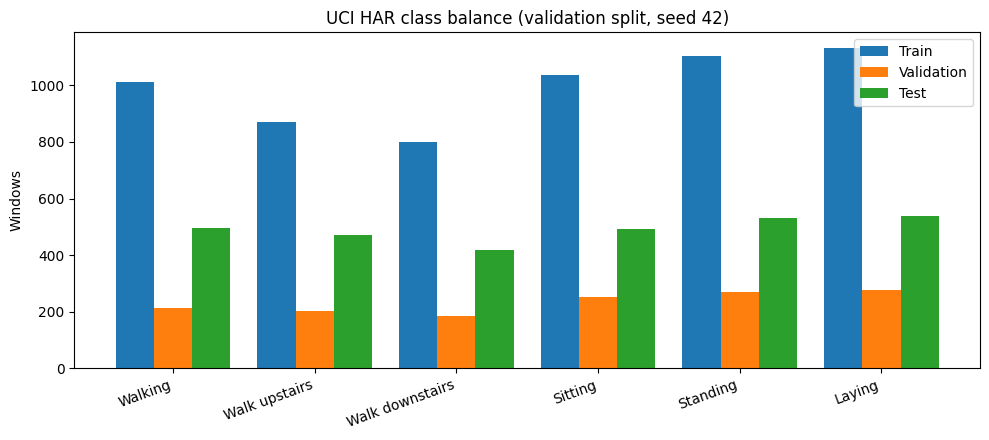

,Train,Validation,Test
Walking,1012,214,496
Walk upstairs,870,203,471
Walk downstairs,800,186,420
Sitting,1035,251,491
Standing,1104,270,532
Laying,1131,276,537


In [15]:
# 2.6 Class-balance plot (Figure: class balance)
d = prepare_har(SEEDS[0])
counts = {name: np.bincount(d[key], minlength=NUM_CLASSES)
          for name, key in [("Train", "y_train"), ("Validation", "y_val"), ("Test", "y_test")]}

x = np.arange(NUM_CLASSES); w = 0.27
plt.figure(figsize=(10, 4.5))
for i, (name, c) in enumerate(counts.items()):
    plt.bar(x + (i - 1) * w, c, w, label=name)
plt.xticks(x, CLASS_NAMES, rotation=20, ha="right")
plt.ylabel("Windows"); plt.title(f"UCI HAR class balance (validation split, seed {SEEDS[0]})")
plt.legend(); plt.tight_layout(); savefig("p1_class_balance.png"); plt.show()

display(pd.DataFrame(counts, index=CLASS_NAMES))

## Section 3 — Adding-problem generator (P1.1)
This is the function provided in the brief, unchanged. Data seeds are fixed: train 0, validation 1, test 2. The three model seeds only change initialisation and shuffling.

In [16]:
# 3.1 Generator (verbatim from the brief)
def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)
    x = np.zeros((n, T, 2), dtype=np.float32)
    x[:, :, 0] = rng.random((n, T))
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)
    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1
    y = x[np.arange(n), i1, 0] + x[np.arange(n), i2, 0]
    return x, y.astype(np.float32)

In [17]:
# Test 3.1 — exactly two markers, one per half, target = sum of marked values
def check_adding(x, y):
    T = x.shape[1]
    m = x[:, :, 1]
    assert np.all(m.sum(1) == 2), "not exactly two markers"
    assert np.all(m[:, :T // 2].sum(1) == 1), "first half must hold one marker"
    assert np.all(m[:, T // 2:].sum(1) == 1), "second half must hold one marker"
    assert set(np.unique(m)) <= {0.0, 1.0}
    np.testing.assert_allclose((x[:, :, 0] * m).sum(1), y, atol=1e-6)

ADD_DATA = {}
for T in ADD_LENGTHS:
    ADD_DATA[T] = {"train": make_adding(N_TRAIN, T, 0),
                   "val":   make_adding(N_VAL,   T, 1),
                   "test":  make_adding(N_TEST,  T, 2)}
    for split in ("train", "val", "test"):
        check_adding(*ADD_DATA[T][split])
    const_mse = np.mean((ADD_DATA[T]["test"][1] - 1.0) ** 2)
    print(f"T={T:3d}: tests passed | constant-1.0 test MSE = {const_mse:.4f}")

T= 50: tests passed | constant-1.0 test MSE = 0.1754
T=100: tests passed | constant-1.0 test MSE = 0.1697
T=200: tests passed | constant-1.0 test MSE = 0.1679
T=400: tests passed | constant-1.0 test MSE = 0.1527


## Section 4 — RNN, LSTM and GRU cells from scratch (P1.2)

**Parameter counts by hand** (d = 9 inputs, h = 64 hidden units, one bias vector per gate):

| Cell | Formula | Value |
|---|---|---|
| RNN  | h·d + h·h + h = 64·9 + 64·64 + 64 | **4,736** |
| LSTM | 4(h·d + h·h + h) | **18,944** |
| GRU  | 3(h·d + h·h + h) | **14,208** |

**Why PyTorch reports more.** `nn.RNN`, `nn.LSTM` and `nn.GRU` keep **two** bias vectors per gate, `bias_ih` and `bias_hh`. That adds h, 4h and 3h parameters: 4,736 + 64 = **4,800**, 18,944 + 256 = **19,200**, 14,208 + 192 = **14,400**. For RNN and LSTM the two biases are only ever summed, so one of them is redundant. For the GRU the candidate's `b_hn` sits inside the reset gate product r ⊙ (W_hn h + b_hn), so it is not redundant there. My cells keep both biases so the weights can be copied one-to-one.

The equivalence tests run on CPU in float32 with a random batch of 32 sequences × 10 steps and random initial states.

In [18]:
# 4.0 Shared test batch and a reference-copy helper
torch.manual_seed(0)
B, T_CHECK, D, H = 32, 10, INPUT_SIZE, HIDDEN_SIZE
x_check = torch.randn(B, T_CHECK, D)     # (batch, time, input)
h0_check = torch.randn(1, B, H)          # (layers, batch, hidden)
c0_check = torch.randn(1, B, H)

def copy_from_library(my_cell, lib_layer):
    with torch.no_grad():
        for n in ("weight_ih", "weight_hh", "bias_ih", "bias_hh"):
            getattr(my_cell, n).copy_(getattr(lib_layer, n + "_l0"))

In [19]:
# 4.1 MyRNNCell (my own implementation; shape comments only were added)
class MyRNNCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super(MyRNNCell, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.weight_ih = nn.Parameter(torch.Tensor(hidden_size, input_size))   # (h, d)
        self.weight_hh = nn.Parameter(torch.Tensor(hidden_size, hidden_size))  # (h, h)
        self.bias_ih = nn.Parameter(torch.Tensor(hidden_size))                 # (h,)
        self.bias_hh = nn.Parameter(torch.Tensor(hidden_size))                 # (h,)
        self.init_weights()

    def init_weights(self):
        stdv = 1.0 / math.sqrt(self.hidden_size) if self.hidden_size > 0 else 0
        for weight in self.parameters():
            nn.init.uniform_(weight, -stdv, stdv)

    def forward(self, x, h_previous):
        # x: (B, d), h_previous: (B, h)  ->  h_t: (B, h)
        # h_t = tanh(x W_ih^T + b_ih + h_{t-1} W_hh^T + b_hh)
        h_t = torch.tanh(
            torch.matmul(x, self.weight_ih.t()) + self.bias_ih +
            torch.matmul(h_previous, self.weight_hh.t()) + self.bias_hh
        )
        return h_t

In [20]:
# Test 4.1 — MyRNNCell matches nn.RNN within 1e-5; parameter count reconciled
ref_rnn = nn.RNN(D, H, batch_first=True, nonlinearity="tanh")
my_rnn = MyRNNCell(D, H); copy_from_library(my_rnn, ref_rnn)

with torch.no_grad():
    ref_out, _ = ref_rnn(x_check, h0_check)              # (B, T, h)
    h = h0_check[0]; outs = []
    for t in range(T_CHECK):
        h = my_rnn(x_check[:, t], h); outs.append(h)
    my_out = torch.stack(outs, 1)                         # (B, T, h)

rnn_diff = (ref_out - my_out).abs().max().item()
print(f"RNN max |diff| = {rnn_diff:.2e}")
assert rnn_diff < 1e-5
assert count_params(my_rnn) == count_params(ref_rnn) == 4800
assert H * D + H * H + H == 4736
print("MyRNNCell tests passed.")

RNN max |diff| = 1.49e-07
MyRNNCell tests passed.


In [21]:
# 4.2 MyLSTMCell (my own implementation; shape comments only were added)
class MyLSTMCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(MyLSTMCell, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        # Gates stacked in PyTorch order (i, f, g, o)
        self.weight_ih = nn.Parameter(torch.Tensor(4 * hidden_size, input_size))   # (4h, d)
        self.weight_hh = nn.Parameter(torch.Tensor(4 * hidden_size, hidden_size))  # (4h, h)
        self.bias_ih = nn.Parameter(torch.Tensor(4 * hidden_size))                 # (4h,)
        self.bias_hh = nn.Parameter(torch.Tensor(4 * hidden_size))                 # (4h,)
        self.init_weights()

    def init_weights(self):
        stdv = 1.0 / math.sqrt(self.hidden_size) if self.hidden_size > 0 else 0
        for weight in self.parameters():
            nn.init.uniform_(weight, -stdv, stdv)

    def forward(self, x, h_previous, c_previous):
        # x: (B, d), h_previous: (B, h), c_previous: (B, h)
        gates_ih = torch.matmul(x, self.weight_ih.t()) + self.bias_ih           # (B, 4h)
        gates_hh = torch.matmul(h_previous, self.weight_hh.t()) + self.bias_hh  # (B, 4h)
        gates = gates_ih + gates_hh                                             # (B, 4h)

        i, f, g, o = gates.chunk(4, dim=1)                                      # each (B, h)
        i = torch.sigmoid(i)        # input gate
        f = torch.sigmoid(f)        # forget gate
        g = torch.tanh(g)           # candidate cell
        o = torch.sigmoid(o)        # output gate

        c_t = f * c_previous + i * g                                            # (B, h)
        h_t = o * torch.tanh(c_t)                                               # (B, h)
        return h_t, c_t

In [22]:
# Test 4.2 — MyLSTMCell matches nn.LSTM (outputs and final cell state) within 1e-5
ref_lstm = nn.LSTM(D, H, batch_first=True)
my_lstm = MyLSTMCell(D, H); copy_from_library(my_lstm, ref_lstm)

with torch.no_grad():
    ref_out, (ref_h, ref_c) = ref_lstm(x_check, (h0_check, c0_check))
    h, c = h0_check[0], c0_check[0]; outs = []
    for t in range(T_CHECK):
        h, c = my_lstm(x_check[:, t], h, c); outs.append(h)
    my_out = torch.stack(outs, 1)

lstm_diff = max((ref_out - my_out).abs().max().item(), (ref_c[0] - c).abs().max().item())
print(f"LSTM max |diff| (outputs and cell state) = {lstm_diff:.2e}")
assert lstm_diff < 1e-5
assert count_params(my_lstm) == count_params(ref_lstm) == 19200
assert 4 * (H * D + H * H + H) == 18944
print("MyLSTMCell tests passed.")

LSTM max |diff| (outputs and cell state) = 1.19e-07
MyLSTMCell tests passed.


In [23]:
# 4.3 MyGRUCell (my own implementation; shape comments only were added)
class MyGRUCell(nn.Module):
    def __init__(self, input_size, hidden_size):
        super(MyGRUCell, self).__init__()
        self.input_size = input_size
        self.hidden_size = hidden_size
        # Gates stacked in PyTorch order (r, z, n)
        self.weight_ih = nn.Parameter(torch.Tensor(3 * hidden_size, input_size))   # (3h, d)
        self.weight_hh = nn.Parameter(torch.Tensor(3 * hidden_size, hidden_size))  # (3h, h)
        self.bias_ih = nn.Parameter(torch.Tensor(3 * hidden_size))                 # (3h,)
        self.bias_hh = nn.Parameter(torch.Tensor(3 * hidden_size))                 # (3h,)
        self.init_weights()

    def init_weights(self):
        stdv = 1.0 / math.sqrt(self.hidden_size) if self.hidden_size > 0 else 0
        for weight in self.parameters():
            nn.init.uniform_(weight, -stdv, stdv)

    def forward(self, x, h_previous):
        # x: (B, d), h_previous: (B, h)
        gates_ih = torch.matmul(x, self.weight_ih.t()) + self.bias_ih           # (B, 3h)
        gates_hh = torch.matmul(h_previous, self.weight_hh.t()) + self.bias_hh  # (B, 3h)

        r_ih, z_ih, n_ih = gates_ih.chunk(3, dim=1)                             # each (B, h)
        r_hh, z_hh, n_hh = gates_hh.chunk(3, dim=1)

        r = torch.sigmoid(r_ih + r_hh)          # reset gate
        z = torch.sigmoid(z_ih + z_hh)          # update gate
        n = torch.tanh(n_ih + r * n_hh)         # candidate (reset applied to W_hn h + b_hn)

        h_t = (1 - z) * n + z * h_previous                                      # (B, h)
        return h_t

In [24]:
# Test 4.3 — MyGRUCell matches nn.GRU within 1e-5
ref_gru = nn.GRU(D, H, batch_first=True)
my_gru = MyGRUCell(D, H); copy_from_library(my_gru, ref_gru)

with torch.no_grad():
    ref_out, _ = ref_gru(x_check, h0_check)
    h = h0_check[0]; outs = []
    for t in range(T_CHECK):
        h = my_gru(x_check[:, t], h); outs.append(h)
    my_out = torch.stack(outs, 1)

gru_diff = (ref_out - my_out).abs().max().item()
print(f"GRU max |diff| = {gru_diff:.2e}")
assert gru_diff < 1e-5
assert count_params(my_gru) == count_params(ref_gru) == 14400
assert 3 * (H * D + H * H + H) == 14208
print("MyGRUCell tests passed.")

GRU max |diff| = 2.38e-07
MyGRUCell tests passed.


In [25]:
# 4.4 Summary table for the report (Table: cell verification)
cell_table = pd.DataFrame({
    "Cell": MODELS,
    "Max |diff| vs library": [rnn_diff, lstm_diff, gru_diff],
    "Hand count (1 bias)": [4736, 18944, 14208],
    "My cell (2 biases)": [count_params(my_rnn), count_params(my_lstm), count_params(my_gru)],
    "PyTorch": [count_params(ref_rnn), count_params(ref_lstm), count_params(ref_gru)],
})
cell_table["Extra bias"] = cell_table["PyTorch"] - cell_table["Hand count (1 bias)"]
cell_table["Pass (<1e-5)"] = cell_table["Max |diff| vs library"] < 1e-5
display(cell_table)

,Cell,Max |diff| vs library,Hand count (1 bias),My cell (2 biases),PyTorch,Extra bias,Pass (<1e-5)
0,RNN,1.490116e-07,4736,4800,4800,64,True
1,LSTM,1.192093e-07,18944,19200,19200,256,True
2,GRU,2.384186e-07,14208,14400,14400,192,True


## Section 5 — HAR classification (P1.3)
Each model reads all 128 steps and classifies from the last hidden state. The cuDNN layers (`nn.RNN`, `nn.LSTM`, `nn.GRU`) are used here for speed, which the brief allows. All three models get the same budget: hidden 64, Adam lr 1e-3, batch 128, `HAR_EPOCHS` epochs, and 3 seeds each.

In [26]:
# 5.1 Models and train/eval functions
RNN_LAYERS = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}

class SeqClassifier(nn.Module):
    def __init__(self, model_type, input_size, hidden_size, num_classes):
        super().__init__()
        self.model_type = model_type
        self.recurrent = RNN_LAYERS[model_type](input_size, hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, num_classes)

    def forward(self, x):                      # x: (B, T, d)
        out, _ = self.recurrent(x)             # out: (B, T, h)
        return self.head(out[:, -1])           # last hidden state -> (B, classes)

def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total, preds, labels = 0.0, [], []
    with torch.set_grad_enabled(train):
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * len(y)
            preds.append(logits.argmax(1).cpu()); labels.append(y.cpu())
    preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
    return (total / len(loader.dataset), accuracy_score(labels, preds),
            f1_score(labels, preds, average="macro"), preds, labels)

def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

def train_har(model_type, seed, hidden=HIDDEN_SIZE, epochs=HAR_EPOCHS, verbose=True):
    set_seed(seed)
    tl, vl, te = har_loaders(seed)
    model = SeqClassifier(model_type, INPUT_SIZE, hidden, NUM_CLASSES).to(device)
    opt = optim.Adam(model.parameters(), lr=LR)
    crit = nn.CrossEntropyLoss()
    hist = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_f1, best_state, times = -1, None, []
    for ep in range(epochs):
        sync(); t0 = time.perf_counter()
        tr_loss, *_ = run_epoch(model, tl, crit, opt)
        sync(); times.append(time.perf_counter() - t0)          # training time only
        va_loss, va_acc, va_f1, *_ = run_epoch(model, vl, crit)
        hist["train_loss"].append(tr_loss); hist["val_loss"].append(va_loss); hist["val_f1"].append(va_f1)
        if va_f1 > best_f1:
            best_f1, best_state = va_f1, copy.deepcopy(model.state_dict())
        if verbose and (ep + 1) % 10 == 0:
            print(f"  ep {ep+1:2d} | train {tr_loss:.4f} | val acc {va_acc:.4f} | val F1 {va_f1:.4f}")
    model.load_state_dict(best_state)
    _, te_acc, te_f1, te_pred, te_lab = run_epoch(model, te, crit)
    return dict(model=model, hist=hist, best_val_f1=best_f1, test_acc=te_acc, test_f1=te_f1,
                params=count_params(model), sec_per_epoch=float(np.mean(times)),
                pred=te_pred, labels=te_lab)

In [27]:
# Test 5.1 — output shape and parameter count (layer + 6-way head)
_m = SeqClassifier("LSTM", INPUT_SIZE, HIDDEN_SIZE, NUM_CLASSES)
assert _m(torch.randn(4, SEQ_LEN_HAR, INPUT_SIZE)).shape == (4, NUM_CLASSES)
assert count_params(_m) == 19200 + HIDDEN_SIZE * NUM_CLASSES + NUM_CLASSES
print("Classifier shape test passed.")

Classifier shape test passed.


In [28]:
# 5.2 Train 3 models x 3 seeds
har_runs = {}
for m in MODELS:
    for s in SEEDS:
        print(f"HAR | {m} | seed {s}")
        r = train_har(m, s)
        har_runs[(m, s)] = r
        log_result(problem="P1_HAR", model=m, seed=s, seq_len=SEQ_LEN_HAR,
                   test_acc=r["test_acc"], macro_f1=r["test_f1"], params=r["params"],
                   sec_per_epoch=r["sec_per_epoch"], notes=f"h={HIDDEN_SIZE}; epochs={HAR_EPOCHS}")
        print(f"  -> test acc {r['test_acc']:.4f} | macro-F1 {r['test_f1']:.4f}")

HAR | RNN | seed 42
  ep 10 | train 0.7237 | val acc 0.7236 | val F1 0.7039
  ep 20 | train 0.6705 | val acc 0.7507 | val F1 0.7298
  ep 30 | train 0.3561 | val acc 0.7621 | val F1 0.7435
  -> test acc 0.7421 | macro-F1 0.7366
HAR | RNN | seed 123
  ep 10 | train 1.0624 | val acc 0.6380 | val F1 0.5550
  ep 20 | train 0.4984 | val acc 0.7754 | val F1 0.7325
  ep 30 | train 0.7404 | val acc 0.7060 | val F1 0.6496
  -> test acc 0.7465 | macro-F1 0.7355
HAR | RNN | seed 2026
  ep 10 | train 0.5997 | val acc 0.7140 | val F1 0.6832
  ep 20 | train 0.4493 | val acc 0.7247 | val F1 0.6524
  ep 30 | train 0.5923 | val acc 0.7803 | val F1 0.7579
  -> test acc 0.8290 | macro-F1 0.8253
HAR | LSTM | seed 42
  ep 10 | train 0.2475 | val acc 0.8364 | val F1 0.8377
  ep 20 | train 0.1678 | val acc 0.8793 | val F1 0.8820
  ep 30 | train 0.1355 | val acc 0.8486 | val F1 0.8570
  -> test acc 0.8924 | macro-F1 0.8928
HAR | LSTM | seed 123
  ep 10 | train 0.2815 | val acc 0.9135 | val F1 0.9137
  ep 20 | 

In [29]:
# 5.3 Results table (Table: HAR results, mean ± std over 3 seeds)
har_df = pd.DataFrame([{"model": m, "seed": s, "test_acc": r["test_acc"], "macro_f1": r["test_f1"],
                        "params": r["params"], "sec_per_epoch": r["sec_per_epoch"]}
                       for (m, s), r in har_runs.items()])
display(har_df.round(4))

def pm(series, scale=1, nd=2):
    return f"{series.mean()*scale:.{nd}f} ± {series.std()*scale:.{nd}f}"

def summarize(df, keys):
    # One row per group: accuracy, macro-F1, params, time as mean ± std over seeds
    rows = []
    for k, g in df.groupby(keys, sort=False):
        k = k if isinstance(k, tuple) else (k,)
        rows.append({**dict(zip(keys, k)),
                     "Test accuracy (%)": pm(g.test_acc, 100),
                     "Macro-F1": pm(g.macro_f1, 1, 4),
                     "Parameters": int(g.params.iloc[0]),
                     "s / epoch": pm(g.sec_per_epoch, 1, 3)})
    return pd.DataFrame(rows).set_index(keys)

har_table = summarize(har_df, ["model"])
display(har_table)

,model,seed,test_acc,macro_f1,params,sec_per_epoch
0,RNN,42,0.7421,0.7366,5190,0.2117
1,RNN,123,0.7465,0.7355,5190,0.1664
2,RNN,2026,0.8290,0.8253,5190,0.1841
3,LSTM,42,0.8924,0.8928,19590,0.1802
4,LSTM,123,0.8795,0.8793,19590,0.2029
5,LSTM,2026,0.8856,0.8860,19590,0.1788
6,GRU,42,0.8873,0.8870,14790,0.1939
7,GRU,123,0.8938,0.8950,14790,0.1646
8,GRU,2026,0.8985,0.8991,14790,0.1853


,Test accuracy (%),Macro-F1,Parameters,s / epoch
model,,,,
RNN,77.25 ± 4.89,0.7658 ± 0.0515,5190,0.187 ± 0.023
LSTM,88.59 ± 0.65,0.8860 ± 0.0068,19590,0.187 ± 0.014
GRU,89.32 ± 0.56,0.8937 ± 0.0062,14790,0.181 ± 0.015


Best run: GRU seed 123 | val F1 0.9767 | test acc 0.8938 | test F1 0.8950


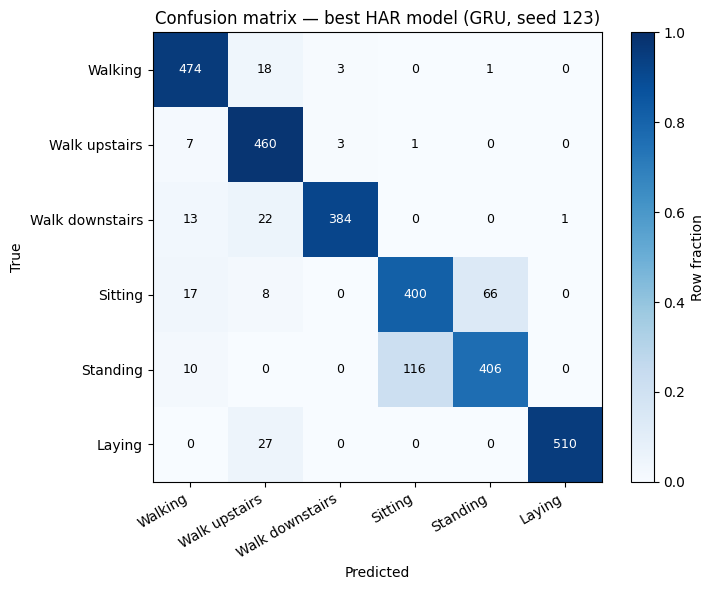

In [30]:
# 5.4 Confusion matrix of the best model (selected on validation macro-F1, not test)
best_key = max(har_runs, key=lambda k: har_runs[k]["best_val_f1"])
best = har_runs[best_key]
cm = confusion_matrix(best["labels"], best["pred"], labels=range(NUM_CLASSES))
print(f"Best run: {best_key[0]} seed {best_key[1]} | val F1 {best['best_val_f1']:.4f} | "
      f"test acc {best['test_acc']:.4f} | test F1 {best['test_f1']:.4f}")

cm_norm = cm / cm.sum(1, keepdims=True)
plt.figure(figsize=(7.5, 6))
plt.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1); plt.colorbar(label="Row fraction")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm_norm[i, j] > 0.5 else "black", fontsize=9)
plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=30, ha="right")
plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
plt.xlabel("Predicted"); plt.ylabel("True")
plt.title(f"Confusion matrix — best HAR model ({best_key[0]}, seed {best_key[1]})")
plt.tight_layout(); savefig("p1_har_confusion_best.png"); plt.show()

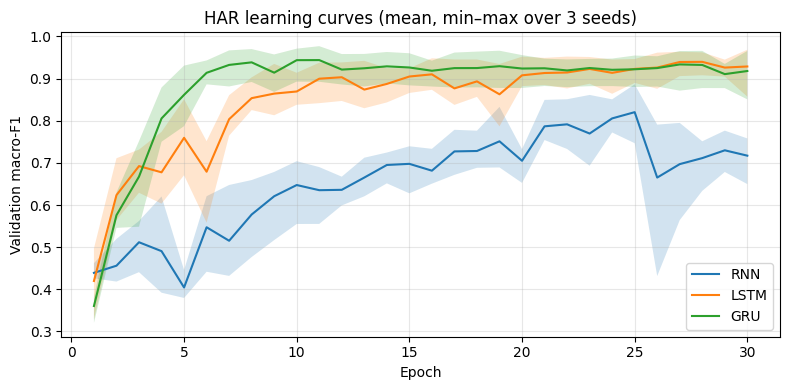

In [31]:
# 5.5 Validation macro-F1 curves (supporting figure)
plt.figure(figsize=(8, 4))
for m in MODELS:
    curves = np.array([har_runs[(m, s)]["hist"]["val_f1"] for s in SEEDS])
    ep = np.arange(1, curves.shape[1] + 1)
    plt.plot(ep, curves.mean(0), label=m)
    plt.fill_between(ep, curves.min(0), curves.max(0), alpha=0.2)
plt.xlabel("Epoch"); plt.ylabel("Validation macro-F1"); plt.title("HAR learning curves (mean, min–max over 3 seeds)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); savefig("p1_har_learning_curves.png"); plt.show()

## Section 6 — Adding problem (P1.4)
T ∈ {50, 100, 200, 400} × {RNN, LSTM, GRU} × 3 seeds = 36 runs. The regression is read from the last hidden state with MSE loss. The main comparison uses **no gradient clipping** because clipping is the subject of the Section 7 ablation. A run counts as **solved** if its test MSE is below 0.05. The baseline is the constant prediction 1.0, at about 0.167.

In [32]:
# 6.1 Model, loaders, training loop (records the pre-clip gradient norm every epoch)
class SeqRegressor(nn.Module):
    def __init__(self, model_type, hidden_size=HIDDEN_SIZE, input_size=2):
        super().__init__()
        self.model_type = model_type
        self.hidden_size = hidden_size
        self.recurrent = RNN_LAYERS[model_type](input_size, hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):                  # x: (B, T, 2)
        out, _ = self.recurrent(x)         # (B, T, h)
        return self.head(out[:, -1]).squeeze(-1)   # (B,)

def adding_loaders(T, seed):
    dd = ADD_DATA[T]
    return (make_loader(*dd["train"], True, seed, torch.float32),
            make_loader(*dd["val"],  False, 0, torch.float32),
            make_loader(*dd["test"], False, 0, torch.float32))

def eval_mse(model, loader):
    model.eval(); total = 0.0
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            total += nn.functional.mse_loss(model(X), y, reduction="sum").item()
    return total / len(loader.dataset)

def train_adding(model_type, T, seed, epochs=ADD_EPOCHS, clip=None, hidden=HIDDEN_SIZE, keep_init=False):
    set_seed(seed)
    tl, vl, te = adding_loaders(T, seed)
    model = SeqRegressor(model_type, hidden).to(device)
    init_state = copy.deepcopy(model.state_dict()) if keep_init else None
    opt = optim.Adam(model.parameters(), lr=LR)
    hist = {"train_mse": [], "val_mse": [], "grad_norm": []}
    best_val, best_state, times = float("inf"), None, []
    for ep in range(epochs):
        model.train(); sync(); t0 = time.perf_counter()
        tot, gnorms = 0.0, []
        for X, y in tl:
            X, y = X.to(device), y.to(device)
            loss = nn.functional.mse_loss(model(X), y)
            opt.zero_grad(); loss.backward()
            # clip_grad_norm_ returns the norm BEFORE clipping; max_norm=inf means "measure only"
            gn = torch.nn.utils.clip_grad_norm_(model.parameters(), clip if clip is not None else float("inf"))
            gnorms.append(gn.item())
            opt.step()
            tot += loss.item() * len(y)
        sync(); times.append(time.perf_counter() - t0)
        val = eval_mse(model, vl)
        hist["train_mse"].append(tot / len(tl.dataset)); hist["val_mse"].append(val)
        hist["grad_norm"].append(float(np.mean(gnorms)))
        if val < best_val:
            best_val, best_state = val, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return dict(model=model, hist=hist, best_val=best_val, test_mse=eval_mse(model, te),
                params=count_params(model), sec_per_epoch=float(np.mean(times)), init_state=init_state)

In [33]:
# Test 6.1 — output shape; baseline check on the test set
_r = SeqRegressor("GRU")
assert _r(torch.randn(5, 50, 2)).shape == (5,)
_y = ADD_DATA[100]["test"][1]
assert abs(np.mean((_y - 1.0) ** 2) - MSE_BASELINE) < 0.02
print("Regressor tests passed.")

Regressor tests passed.


In [34]:
# 6.2 36 runs. The T=100, seed-0 models (initial + trained) are kept for the Section 7(a) gradient study.
add_runs = {}
for T in ADD_LENGTHS:
    for m in MODELS:
        for s in SEEDS:
            r = train_adding(m, T, s, keep_init=(T == T_GRADIENT and s == SEEDS[0]))
            add_runs[(T, m, s)] = r
            solved = r["test_mse"] < SOLVED_THRESHOLD
            log_result(problem="P1_ADD", model=m, seed=s, seq_len=T, test_mse=r["test_mse"],
                       params=r["params"], sec_per_epoch=r["sec_per_epoch"],
                       notes=f"{'solved' if solved else 'unsolved'}; no clipping; epochs={ADD_EPOCHS}")
            print(f"T={T:3d} | {m:4s} | seed {s:4d} | test MSE {r['test_mse']:.4f} | "
                  f"{'SOLVED' if solved else '-'} | {r['sec_per_epoch']:.2f}s/ep")

T= 50 | RNN  | seed   42 | test MSE 0.1684 | - | 0.27s/ep
T= 50 | RNN  | seed  123 | test MSE 0.1743 | - | 0.25s/ep
T= 50 | RNN  | seed 2026 | test MSE 0.1712 | - | 0.27s/ep
T= 50 | LSTM | seed   42 | test MSE 0.0142 | SOLVED | 0.29s/ep
T= 50 | LSTM | seed  123 | test MSE 0.0071 | SOLVED | 0.27s/ep
T= 50 | LSTM | seed 2026 | test MSE 0.0051 | SOLVED | 0.29s/ep
T= 50 | GRU  | seed   42 | test MSE 0.0016 | SOLVED | 0.29s/ep
T= 50 | GRU  | seed  123 | test MSE 0.0017 | SOLVED | 0.27s/ep
T= 50 | GRU  | seed 2026 | test MSE 0.0019 | SOLVED | 0.28s/ep
T=100 | RNN  | seed   42 | test MSE 0.1700 | - | 0.27s/ep
T=100 | RNN  | seed  123 | test MSE 0.1703 | - | 0.26s/ep
T=100 | RNN  | seed 2026 | test MSE 0.1703 | - | 0.27s/ep
T=100 | LSTM | seed   42 | test MSE 0.1698 | - | 0.30s/ep
T=100 | LSTM | seed  123 | test MSE 0.0250 | SOLVED | 0.29s/ep
T=100 | LSTM | seed 2026 | test MSE 0.0157 | SOLVED | 0.27s/ep
T=100 | GRU  | seed   42 | test MSE 0.0016 | SOLVED | 0.28s/ep
T=100 | GRU  | seed  123 | 

In [35]:
# 6.3 Tables: test MSE mean ± std, and solved runs out of 3 (Tables: adding MSE, solved runs)
add_df = pd.DataFrame([{"T": T, "model": m, "seed": s, "test_mse": r["test_mse"],
                        "solved": r["test_mse"] < SOLVED_THRESHOLD, "sec_per_epoch": r["sec_per_epoch"]}
                       for (T, m, s), r in add_runs.items()])

mse_table = add_df.groupby(["model", "T"]).test_mse.apply(lambda g: f"{g.mean():.4f} ± {g.std():.4f}") \
                  .unstack("T").reindex(MODELS)
mse_table["baseline"] = f"≈{MSE_BASELINE}"
print("Test MSE (mean ± std over 3 seeds)"); display(mse_table)

solved_table = add_df.groupby(["model", "T"]).solved.sum().unstack("T").reindex(MODELS).astype(int)
print("Solved runs (test MSE < 0.05) out of 3"); display(solved_table)

Test MSE (mean ± std over 3 seeds)


T,50,100,200,400,baseline
model,,,,,
RNN,0.1713 ± 0.0030,0.1702 ± 0.0002,0.1683 ± 0.0002,0.1538 ± 0.0005,≈0.167
LSTM,0.0088 ± 0.0048,0.0702 ± 0.0864,0.1685 ± 0.0005,0.1536 ± 0.0001,≈0.167
GRU,0.0017 ± 0.0001,0.0018 ± 0.0002,0.0016 ± 0.0003,0.0042 ± 0.0007,≈0.167


Solved runs (test MSE < 0.05) out of 3


T,50,100,200,400
model,,,,
RNN,0,0,0,0
LSTM,3,2,0,0
GRU,3,3,3,3


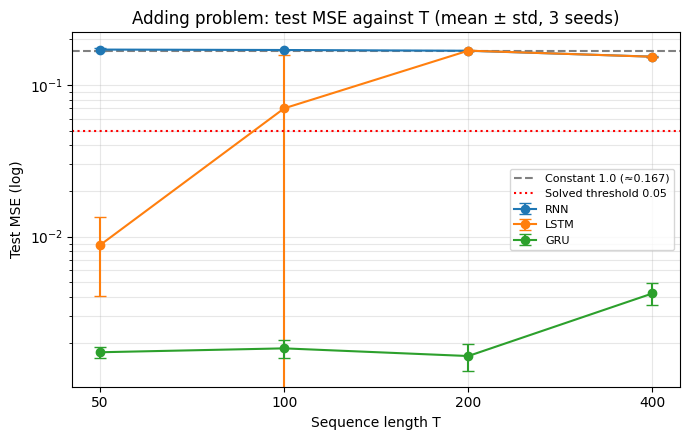

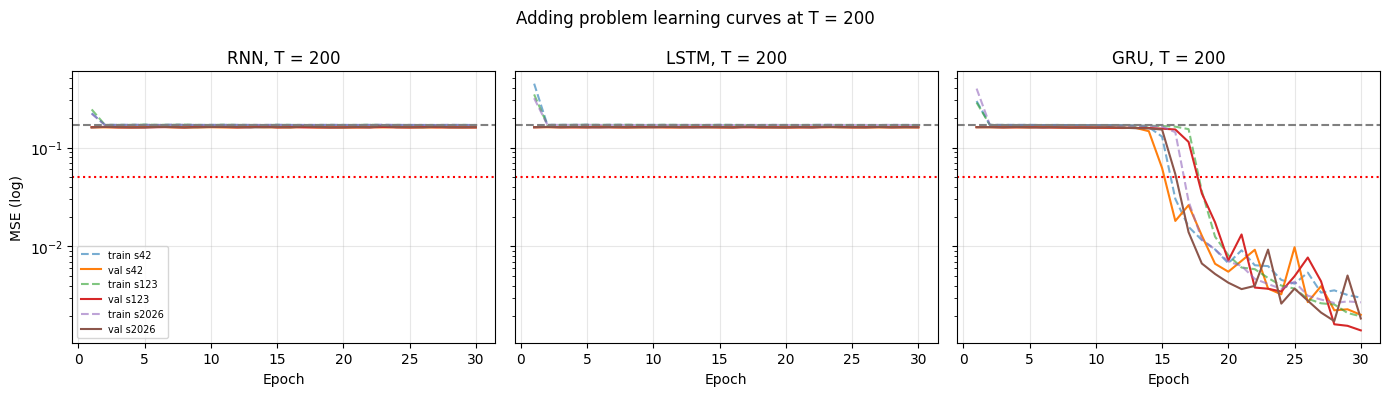

In [36]:
# 6.4 Figures: MSE against T, and learning curves at T = 200
fig, ax = plt.subplots(figsize=(7, 4.5))
for m in MODELS:
    g = add_df[add_df.model == m].groupby("T").test_mse
    ax.errorbar(ADD_LENGTHS, g.mean().values, yerr=g.std().values, marker="o", capsize=4, label=m)
ax.axhline(MSE_BASELINE, ls="--", c="grey", label="Constant 1.0 (≈0.167)")
ax.axhline(SOLVED_THRESHOLD, ls=":", c="red", label="Solved threshold 0.05")
ax.set_xscale("log", base=2); ax.set_xticks(ADD_LENGTHS); ax.set_xticklabels(ADD_LENGTHS)
ax.set_yscale("log"); ax.set_xlabel("Sequence length T"); ax.set_ylabel("Test MSE (log)")
ax.set_title("Adding problem: test MSE against T (mean ± std, 3 seeds)")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
plt.tight_layout(); savefig("p1_adding_mse_vs_T.png"); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, m in zip(axes, MODELS):
    for s in SEEDS:
        h = add_runs[(T_ABLATION, m, s)]["hist"]
        ep = np.arange(1, len(h["val_mse"]) + 1)
        ax.plot(ep, h["train_mse"], ls="--", alpha=0.6, label=f"train s{s}")
        ax.plot(ep, h["val_mse"], label=f"val s{s}")
    ax.axhline(MSE_BASELINE, ls="--", c="grey"); ax.axhline(SOLVED_THRESHOLD, ls=":", c="red")
    ax.set_yscale("log"); ax.set_title(f"{m}, T = {T_ABLATION}"); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
axes[0].set_ylabel("MSE (log)"); axes[0].legend(fontsize=7)
plt.suptitle("Adding problem learning curves at T = 200"); plt.tight_layout()
savefig("p1_adding_curves_T200.png"); plt.show()

## Section 7 — Gradients, ablations and analysis (P1.5)

### 7(a) Gradient norm ‖∂L/∂hₜ‖ against t at T = 100, before and after training
The cuDNN layers don't expose the intermediate hidden states. To get them I copy the weights into **my own verified cells from Section 4** and unroll step by step. Each hₜ keeps its gradient through `retain_grad()`. The models are the T = 100, seed-42 runs from Section 6, measured at initialisation and at their best checkpoint, on a fixed batch of 256 test sequences.

In [37]:
# 7.1 Unroll with my cells and record ||dL/dh_t|| for every t
MY_CELLS = {"RNN": MyRNNCell, "LSTM": MyLSTMCell, "GRU": MyGRUCell}

def hidden_grad_norms(model_type, state_dict, X, y, hidden=HIDDEN_SIZE):
    cell = MY_CELLS[model_type](2, hidden).to(device)
    head = nn.Linear(hidden, 1).to(device)
    with torch.no_grad():
        for n in ("weight_ih", "weight_hh", "bias_ih", "bias_hh"):
            getattr(cell, n).copy_(state_dict[f"recurrent.{n}_l0"])
        head.weight.copy_(state_dict["head.weight"]); head.bias.copy_(state_dict["head.bias"])

    B = X.size(0)
    h = X.new_zeros(B, hidden)              # (B, h)
    c = X.new_zeros(B, hidden)              # (B, h), LSTM only
    hs = []
    for t in range(X.size(1)):
        if model_type == "LSTM":
            h, c = cell(X[:, t], h, c)
        else:
            h = cell(X[:, t], h)
        h.retain_grad(); hs.append(h)
    loss = nn.functional.mse_loss(head(h).squeeze(-1), y)
    loss.backward()
    return np.array([ht.grad.norm(dim=1).mean().item() for ht in hs]), loss.item()

Xg = torch.as_tensor(ADD_DATA[T_GRADIENT]["test"][0][:256], device=device)
yg = torch.as_tensor(ADD_DATA[T_GRADIENT]["test"][1][:256], device=device)

grad_before, grad_after = {}, {}
for m in MODELS:
    run = add_runs[(T_GRADIENT, m, SEEDS[0])]
    grad_before[m], l0 = hidden_grad_norms(m, run["init_state"], Xg, yg)
    grad_after[m],  l1 = hidden_grad_norms(m, run["model"].state_dict(), Xg, yg)
    print(f"{m:4s} | batch MSE init {l0:.4f} -> trained {l1:.4f} | "
          f"||dL/dh_1|| / ||dL/dh_T||: before {grad_before[m][0]/grad_before[m][-1]:.2e}, "
          f"after {grad_after[m][0]/grad_after[m][-1]:.2e}")

RNN  | batch MSE init 0.9486 -> trained 0.1685 | ||dL/dh_1|| / ||dL/dh_T||: before 0.00e+00, after 0.00e+00
LSTM | batch MSE init 1.4363 -> trained 0.1674 | ||dL/dh_1|| / ||dL/dh_T||: before 1.74e-20, after 3.74e-11
GRU  | batch MSE init 1.0503 -> trained 0.0012 | ||dL/dh_1|| / ||dL/dh_T||: before 4.44e-20, after 8.89e-01


In [ ]:
# Test 7.1 — the probe built from my cells reproduces the cuDNN model's predictions
for m in MODELS:
    mdl = add_runs[(T_GRADIENT, m, SEEDS[0])]["model"].eval()
    with torch.no_grad():
        lib_loss = nn.functional.mse_loss(mdl(Xg), yg).item()
    _, probe_loss = hidden_grad_norms(m, mdl.state_dict(), Xg, yg)
    assert abs(lib_loss - probe_loss) < 1e-4, (m, lib_loss, probe_loss)
print("Gradient probe matches the trained cuDNN models.")

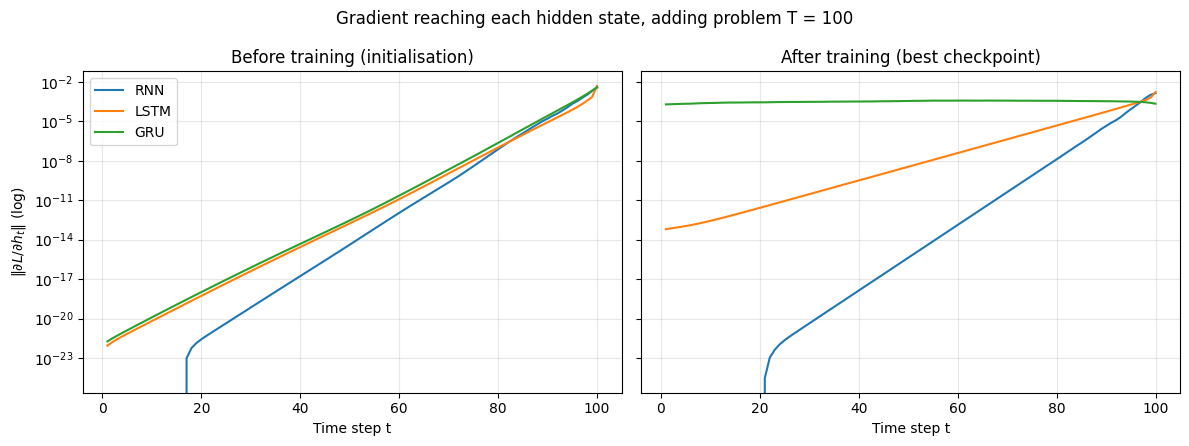

In [38]:
# 7.2 Figure: gradient norm against time step
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
t_axis = np.arange(1, T_GRADIENT + 1)
for ax, (title, g) in zip(axes, [("Before training (initialisation)", grad_before),
                                 ("After training (best checkpoint)", grad_after)]):
    for m in MODELS:
        ax.semilogy(t_axis, g[m], label=m)
    ax.set_title(title); ax.set_xlabel("Time step t"); ax.grid(alpha=0.3, which="both")
axes[0].set_ylabel(r"$\|\partial L/\partial h_t\|$ (log)"); axes[0].legend()
plt.suptitle(f"Gradient reaching each hidden state, adding problem T = {T_GRADIENT}")
plt.tight_layout(); savefig("p1_grad_norm_vs_t.png"); plt.show()

### 7(b) Hidden-size sweep {16, 32, 64, 128} for LSTM and GRU on HAR
Same budget as Section 5. h = 64 is re-run inside the sweep so the whole sweep comes from one loop.

In [39]:
# 7.3 Hidden-size sweep (2 models x 4 sizes x 3 seeds = 24 runs)
sweep_rows = []
for m in ["LSTM", "GRU"]:
    for hsz in HIDDEN_SWEEP:
        for s in SEEDS:
            r = train_har(m, s, hidden=hsz, verbose=False)
            sweep_rows.append({"model": m, "hidden": hsz, "seed": s, "test_acc": r["test_acc"],
                               "macro_f1": r["test_f1"], "params": r["params"], "sec_per_epoch": r["sec_per_epoch"]})
            log_result(problem="P1_HAR_SWEEP", model=m, seed=s, seq_len=SEQ_LEN_HAR,
                       test_acc=r["test_acc"], macro_f1=r["test_f1"], params=r["params"],
                       sec_per_epoch=r["sec_per_epoch"], notes=f"hidden sweep h={hsz}; epochs={HAR_EPOCHS}")
            print(f"{m:4s} h={hsz:3d} seed {s:4d} | acc {r['test_acc']:.4f} | F1 {r['test_f1']:.4f}")

sweep_df = pd.DataFrame(sweep_rows)
sweep_table = summarize(sweep_df, ["model", "hidden"])
display(sweep_table)

LSTM h= 16 seed   42 | acc 0.8663 | F1 0.8653
LSTM h= 16 seed  123 | acc 0.8283 | F1 0.8254
LSTM h= 16 seed 2026 | acc 0.7418 | F1 0.7334
LSTM h= 32 seed   42 | acc 0.8588 | F1 0.8577
LSTM h= 32 seed  123 | acc 0.8700 | F1 0.8696
LSTM h= 32 seed 2026 | acc 0.8476 | F1 0.8461
LSTM h= 64 seed   42 | acc 0.8924 | F1 0.8928
LSTM h= 64 seed  123 | acc 0.8795 | F1 0.8793
LSTM h= 64 seed 2026 | acc 0.8856 | F1 0.8860
LSTM h=128 seed   42 | acc 0.8911 | F1 0.8917
LSTM h=128 seed  123 | acc 0.8921 | F1 0.8943
LSTM h=128 seed 2026 | acc 0.9057 | F1 0.9064
GRU  h= 16 seed   42 | acc 0.8490 | F1 0.8480
GRU  h= 16 seed  123 | acc 0.8609 | F1 0.8604
GRU  h= 16 seed 2026 | acc 0.8772 | F1 0.8767
GRU  h= 32 seed   42 | acc 0.8945 | F1 0.8939
GRU  h= 32 seed  123 | acc 0.8880 | F1 0.8884
GRU  h= 32 seed 2026 | acc 0.9046 | F1 0.9040
GRU  h= 64 seed   42 | acc 0.8873 | F1 0.8870
GRU  h= 64 seed  123 | acc 0.8938 | F1 0.8950
GRU  h= 64 seed 2026 | acc 0.8985 | F1 0.8991
GRU  h=128 seed   42 | acc 0.8951 

Test accuracy (%)         Macro-F1  Parameters      s / epoch
model hidden                                                              
LSTM  16          81.21 ± 6.38  0.8080 ± 0.0676        1830  0.197 ± 0.021
      32          85.88 ± 1.12  0.8578 ± 0.0118        5702  0.184 ± 0.005
      64          88.59 ± 0.65  0.8860 ± 0.0068       19590  0.199 ± 0.004
      128         89.63 ± 0.81  0.8974 ± 0.0079       71942  0.375 ± 0.008
GRU   16          86.23 ± 1.41  0.8617 ± 0.0144        1398  0.176 ± 0.011
      32          89.57 ± 0.84  0.8954 ± 0.0079        4326  0.185 ± 0.013
      64          89.32 ± 0.56  0.8937 ± 0.0062       14790  0.178 ± 0.012
      128         89.76 ± 1.01  0.8976 ± 0.0091       54150  0.244 ± 0.004

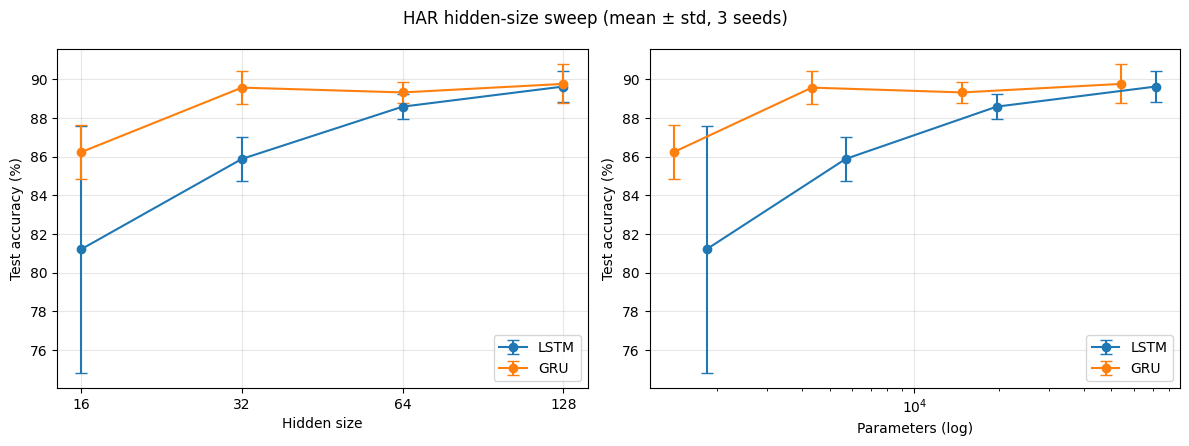

In [40]:
# 7.4 Figure: hidden-size sweep
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m in ["LSTM", "GRU"]:
    g = sweep_df[sweep_df.model == m].groupby("hidden")
    axes[0].errorbar(HIDDEN_SWEEP, g.test_acc.mean() * 100, yerr=g.test_acc.std() * 100,
                     marker="o", capsize=4, label=m)
    axes[1].errorbar(g.params.first(), g.test_acc.mean() * 100, yerr=g.test_acc.std() * 100,
                     marker="o", capsize=4, label=m)
axes[0].set_xscale("log", base=2); axes[0].set_xticks(HIDDEN_SWEEP); axes[0].set_xticklabels(HIDDEN_SWEEP)
axes[0].set_xlabel("Hidden size"); axes[1].set_xscale("log"); axes[1].set_xlabel("Parameters (log)")
for ax in axes:
    ax.set_ylabel("Test accuracy (%)"); ax.grid(alpha=0.3); ax.legend()
plt.suptitle("HAR hidden-size sweep (mean ± std, 3 seeds)"); plt.tight_layout()
savefig("p1_hidden_sweep.png"); plt.show()

### 7(c) Individual ablation — gradient clipping for the vanilla RNN at T = 200 (student ID ends in 0, so even)
**Clip = 1.0** is trained here. **No clipping** reuses the Section 6 RNN runs at T = 200, which have the same seeds, data, epochs and code path. The only difference is `max_norm`. The recorded gradient norm is the value **before** clipping.

In [41]:
# 7.5 Clipped runs
abl = {"none": {s: add_runs[(T_ABLATION, "RNN", s)] for s in SEEDS}, "clip 1.0": {}}
for s in SEEDS:
    r = train_adding("RNN", T_ABLATION, s, clip=CLIP_NORM)
    abl["clip 1.0"][s] = r
    log_result(problem="P1_ABLATION", model="RNN", seed=s, seq_len=T_ABLATION, test_mse=r["test_mse"],
               params=r["params"], sec_per_epoch=r["sec_per_epoch"],
               notes=f"grad clip norm {CLIP_NORM}; {'solved' if r['test_mse'] < SOLVED_THRESHOLD else 'unsolved'}")
    print(f"clip | seed {s} | test MSE {r['test_mse']:.4f}")

abl_table = pd.DataFrame({k: {s: v[s]["test_mse"] for s in SEEDS} for k, v in abl.items()})
abl_table.loc["mean"] = abl_table.mean(); abl_table.loc["std"] = abl_table.iloc[:3].std()
abl_table.loc["solved (/3)"] = [(abl_table.iloc[:3][c] < SOLVED_THRESHOLD).sum() for c in abl_table.columns]
print("RNN, T = 200: test MSE"); display(abl_table.round(4))

clip | seed 42 | test MSE 0.1689
clip | seed 123 | test MSE 0.1682
clip | seed 2026 | test MSE 0.1683
RNN, T = 200: test MSE


,none,clip 1.0
42,0.1685,0.1689
123,0.1681,0.1682
2026,0.1682,0.1683
mean,0.1683,0.1685
std,0.0002,0.0003
solved (/3),0.0000,0.0000


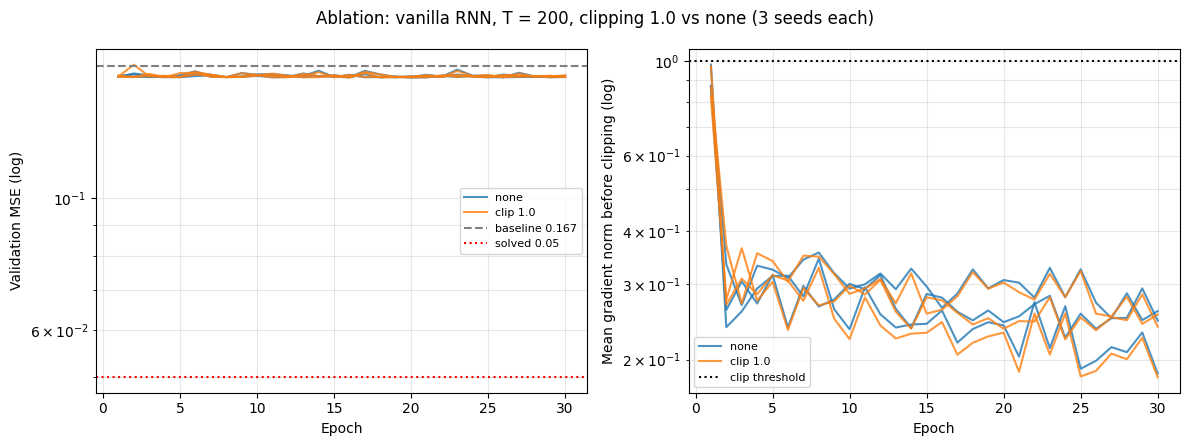

In [42]:
# 7.6 Figure: ablation (validation MSE and pre-clip gradient norm per epoch)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for (name, runs), col in zip(abl.items(), ["tab:blue", "tab:orange"]):
    for i, s in enumerate(SEEDS):
        h = runs[s]["hist"]; ep = np.arange(1, len(h["val_mse"]) + 1)
        axes[0].plot(ep, h["val_mse"], c=col, alpha=0.8, label=name if i == 0 else None)
        axes[1].semilogy(ep, h["grad_norm"], c=col, alpha=0.8, label=name if i == 0 else None)
axes[0].axhline(MSE_BASELINE, ls="--", c="grey", label="baseline 0.167")
axes[0].axhline(SOLVED_THRESHOLD, ls=":", c="red", label="solved 0.05")
axes[0].set_yscale("log"); axes[0].set_ylabel("Validation MSE (log)")
axes[1].axhline(CLIP_NORM, ls=":", c="k", label="clip threshold")
axes[1].set_ylabel("Mean gradient norm before clipping (log)")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
plt.suptitle(f"Ablation: vanilla RNN, T = {T_ABLATION}, clipping 1.0 vs none (3 seeds each)")
plt.tight_layout(); savefig("p1_ablation_rnn_clipping.png"); plt.show()

### 7(d) Analysis
The cell below collects the numbers that the one-page analysis cites. The analysis itself goes in the report, written in my own words from these tables and figures.

In [43]:
# 7.7 Key numbers for the analysis
print("HAR (Section 5):"); display(har_table)
print("Adding problem test MSE (Section 6):"); display(mse_table)
print("Solved runs (Section 6):"); display(solved_table)
print("Clipping ablation (Section 7c):"); display(abl_table.round(4))

for m in MODELS:
    gb, ga = grad_before[m], grad_after[m]
    print(f"{m:4s} gradient ratio ||dL/dh_1||/||dL/dh_100||  before: {gb[0]/gb[-1]:.2e}   after: {ga[0]/ga[-1]:.2e}")

# Model size at h=64 in bytes (float32), for the wearable discussion
for m in MODELS:
    p = har_runs[(m, SEEDS[0])]["params"]
    print(f"{m:4s}: {p:,} params ≈ {p*4/1024:.1f} KB float32 | {har_table.loc[m, 's / epoch']} s/epoch")

HAR (Section 5):


,Test accuracy (%),Macro-F1,Parameters,s / epoch
model,,,,
RNN,77.25 ± 4.89,0.7658 ± 0.0515,5190,0.187 ± 0.023
LSTM,88.59 ± 0.65,0.8860 ± 0.0068,19590,0.187 ± 0.014
GRU,89.32 ± 0.56,0.8937 ± 0.0062,14790,0.181 ± 0.015


Adding problem test MSE (Section 6):


T,50,100,200,400,baseline
model,,,,,
RNN,0.1713 ± 0.0030,0.1702 ± 0.0002,0.1683 ± 0.0002,0.1538 ± 0.0005,≈0.167
LSTM,0.0088 ± 0.0048,0.0702 ± 0.0864,0.1685 ± 0.0005,0.1536 ± 0.0001,≈0.167
GRU,0.0017 ± 0.0001,0.0018 ± 0.0002,0.0016 ± 0.0003,0.0042 ± 0.0007,≈0.167


Solved runs (Section 6):


T,50,100,200,400
model,,,,
RNN,0,0,0,0
LSTM,3,2,0,0
GRU,3,3,3,3


Clipping ablation (Section 7c):


,none,clip 1.0
42,0.1685,0.1689
123,0.1681,0.1682
2026,0.1682,0.1683
mean,0.1683,0.1685
std,0.0002,0.0003
solved (/3),0.0000,0.0000


RNN  gradient ratio ||dL/dh_1||/||dL/dh_100||  before: 0.00e+00   after: 0.00e+00
LSTM gradient ratio ||dL/dh_1||/||dL/dh_100||  before: 1.74e-20   after: 3.74e-11
GRU  gradient ratio ||dL/dh_1||/||dL/dh_100||  before: 4.44e-20   after: 8.89e-01
RNN : 5,190 params ≈ 20.3 KB float32 | 0.187 ± 0.023 s/epoch
LSTM: 19,590 params ≈ 76.5 KB float32 | 0.187 ± 0.014 s/epoch
GRU : 14,790 params ≈ 57.8 KB float32 | 0.181 ± 0.015 s/epoch


**Analysis outline (write each point in the report, citing table and figure numbers):**
1. **Memory and the gradient plot.** How fast ‖∂L/∂hₜ‖ decays as t moves away from T for each model, before and after training. Link this to which models could use the first marker.
2. **Where each model fails as T grows.** Use the solved-runs table and the MSE-against-T plot. At which T does each model stall near 0.167?
3. **Accuracy–parameters–time trade-off on HAR.** Use the HAR table and the hidden-size sweep. Is the extra size of the LSTM worth it compared with the GRU? Where does the sweep flatten out?
4. **Clipping ablation.** Did clipping change the outcome, or only stabilise training? Use the gradient-norm panel. Note that clipping fixes exploding gradients but not vanishing ones.
5. **Wearable recommendation.** Pick one model and justify it from parameters (memory), seconds per epoch (a proxy for compute and energy) and accuracy, all taken from your tables.

In [44]:
# 7.8 Wrap-up: requirements.txt and total run time (for the README)
import matplotlib, sklearn
reqs = (f"torch=={torch.__version__.split('+')[0]}\nnumpy=={np.__version__}\npandas=={pd.__version__}\n"
        f"matplotlib=={matplotlib.__version__}\nscikit-learn=={sklearn.__version__}\n")
(ROOT / "requirements.txt").write_text(reqs)
print(reqs)

final = pd.read_csv(RESULTS_FILE)
print("Problem 1 rows in results.csv:", final.problem.astype(str).str.startswith("P1").sum())
print("Figures saved:", sorted(p.name for p in FIG_DIR.glob("*.png")))
print(f"Total notebook run time: {(time.perf_counter() - NOTEBOOK_START)/60:.1f} min on {device}")

torch==2.14.1
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-learn==1.6.1

Problem 1 rows in results.csv: 72
Figures saved: ['p1_ablation_rnn_clipping.png', 'p1_adding_curves_T200.png', 'p1_adding_mse_vs_T.png', 'p1_class_balance.png', 'p1_grad_norm_vs_t.png', 'p1_har_confusion_best.png', 'p1_har_learning_curves.png', 'p1_hidden_sweep.png']
Total notebook run time: 16.6 min on cuda
